# Bounded complete quantum-simulation resources

Five complete measured circuits cover retargetable dynamics at one/two spins and thermal spectral filtering at one/two spins. The source is explicit QSP with PREPARE/SELECT/unprepare access; the thermal input contains Bell preparation and unconditioned reference discard. Every rejected trial and factory retry is charged in the calculated workloads.

This notebook verifies the saved source/QASM identities and reruns bounded ideal source-instrument checks. Actual Clifford+T synthesis and physical-model reports are loaded from the generated bundle; their large repeated populations and hardware schedules are **unexecuted**. Source intervals, guarded numerical synthesis, a separate SDK reserve, statistics and physical assumptions retain separate scopes. Classical exponentials supply independent answers, never quantum gates.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

root=Path.cwd()
local_module=(root/"complete_resource_workloads.py").is_file()
if not local_module and root.name=="notebooks" and (root.parent/"src/openquantum/simulation/complete_resource_workloads.py").is_file():
    root=root.parent
if not local_module and (root/"src/openquantum/simulation/complete_resource_workloads.py").is_file():
    sys.path.insert(0,str(root/"src"))
    from openquantum.simulation import complete_resource_workloads as cr
    from openquantum import instrument_resources as ir
    asset_dir=root/"assets/generated/simulation/complete-resources"
else:
    sys.path.insert(0,str(root))
    import complete_resource_workloads as cr
    import instrument_resources as ir
    asset_dir=root
# Explicitly restore inline output even if an imported artifact generator used Agg.
get_ipython().run_line_magic("matplotlib","inline")

manifest=json.loads((asset_dir/"manifest.json").read_text())
results=json.loads((asset_dir/"results.json").read_text())
summary=pd.read_csv(asset_dir/"summary.csv")
for name, expected in manifest["artifacts_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for name, expected in manifest["source_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for module in (cr, ir):
    path=Path(module.__file__)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==manifest["source_sha256"][path.name], path.name
for name, expected in manifest["packages"].items():
    assert importlib.metadata.version(name)==expected, name
assert results["repeated_workloads_executed"] is False
assert results["formal_confidence_certificate"] is False
records=results["cases"]
assert set(records)=={f"{kind}-n{n}-{axis}" for kind,n,axis in cr.default_task_specs()}
limits=cr.resource_limits()
print(f"Verified {len(manifest['artifacts_sha256'])} saved artifact hashes and {len(records)} measured group records.")

def table(frame):
    # Native chapter tables carry the publication view; HTML remains useful live.
    display(frame)


Verified 34 saved artifact hashes and 5 measured group records.


## Fresh complete source checks and dynamics output

The dynamics task fixes $H_n=\sum ZZ+0.7\sum X$, $t=0.5$, fresh $|0^n\rangle$ input and accepted $Z_0$. Each resource trial measures success ancillas before all system readouts. The checks below rebuild all five source trials and evaluate their complete ideal instrument, including reset/project/discard events. Reference scores come from independent matrix exponentials.

Saved routed and actual Clifford+T scores are shown alongside the fresh source answer. Their agreement is bounded numerical evidence; it does not certify a whole SDK norm error or physical hardware.

Five fresh source checks and both dynamics final-readout joint-law checks passed; no synthesis or hardware jobs ran.


,task,wires,exact_mean,fresh_source_mean,routed_mean,actual_CT_mean,actual_CT_acceptance,T_and_Tdag
0,dynamics-n1-Z,3,0.764842,0.764842,0.764842,0.764842,0.062501,6128
1,dynamics-n2-Z,6,0.783636,0.783636,0.783636,0.783635,0.062500,31022


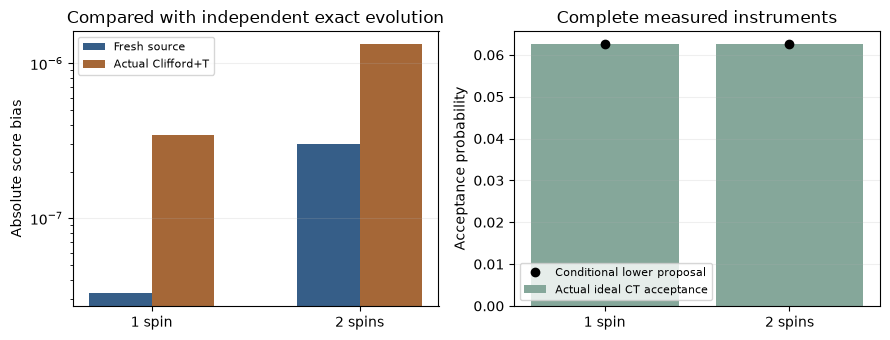

In [2]:
tasks={}
fresh={}
for kind,n,axis in cr.default_task_specs():
    task=cr.build_complete_task(kind,n,axis)
    tasks[task.case_id]=task
    fresh[task.case_id]=ir.simulate_scored_trial(task.source,task.outcome_clbits,task.score_values,task.accept_clbits,limits=limits)
    saved=records[task.case_id]["prepared"]
    assert abs(fresh[task.case_id]["mean"]-saved["source_instrument_check"]["mean"]) < 1e-10
    assert abs(fresh[task.case_id]["acceptance_probability"]-saved["source_instrument_check"]["acceptance_probability"]) < 1e-10
    assert abs(fresh[task.case_id]["mean"]-task.exact_mean) <= saved["error_and_conditioning_contract"]["source_score_bias_upper"]+1e-10
for name in ("dynamics-n1-Z","dynamics-n2-Z"):
    task=tasks[name]
    old_trial=cr.rq.build_measured_trial(task.core)
    all_bits=tuple(range(task.source.num_clbits))
    zero_scores=(0.,)*(2**len(all_bits))
    old_joint=ir.simulate_scored_trial(old_trial,all_bits,zero_scores,limits=limits)["joint_probabilities"]
    new_joint=ir.simulate_scored_trial(task.source,all_bits,zero_scores,limits=limits)["joint_probabilities"]
    assert np.max(np.abs(old_joint-new_joint)) < 1e-12
print("Five fresh source checks and both dynamics final-readout joint-law checks passed; no synthesis or hardware jobs ran.")

dynamics=[]
for name in ("dynamics-n1-Z","dynamics-n2-Z"):
    saved=records[name]["prepared"]
    dynamics.append({"task":name,"wires":saved["source_logical_qubits"],
        "exact_mean":saved["exact_reference_mean"],"fresh_source_mean":fresh[name]["mean"],
        "routed_mean":saved["routed_instrument_check"]["mean"],
        "actual_CT_mean":saved["clifford_t_instrument_check"]["mean"],
        "actual_CT_acceptance":saved["clifford_t_instrument_check"]["acceptance_probability"],
        "T_and_Tdag":sum(saved["full_clifford_t_counts"].get(g,0) for g in ("t","tdg"))})
table(pd.DataFrame(dynamics))
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
x=np.arange(2)
for offset,(key,label,color) in enumerate((("fresh_source_mean","Fresh source","#365e88"),("actual_CT_mean","Actual Clifford+T","#a56737"))):
    axes[0].bar(x+(offset-.5)*.3,[max(abs(r[key]-r["exact_mean"]),1e-16) for r in dynamics],width=.3,label=label,color=color)
axes[0].set(xticks=x,xticklabels=["1 spin","2 spins"],yscale="log",ylabel="Absolute score bias",title="Compared with independent exact evolution")
axes[0].legend(fontsize=8)
axes[1].bar(x,[r["actual_CT_acceptance"] for r in dynamics],color="#85a79a",label="Actual ideal CT acceptance")
axes[1].plot(x,[records[r["task"]]["prepared"]["error_and_conditioning_contract"]["acceptance_lower_proposal"] for r in dynamics],"ko",label="Conditional lower proposal")
axes[1].set(xticks=x,xticklabels=["1 spin","2 spins"],ylabel="Acceptance probability",title="Complete measured instruments")
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Thermal scores, Bell input and acceptance

The fixed thermal chain is $H_n=0.6\sum ZZ+0.35\sum X$ at $\beta=1.5$. One spin has only X. Two spins use separate scores $0.35(x_0+x_1)$ and $0.6z_0z_1$; bits within a trial may be correlated. Complete trials retain Bell input, every success measurement, unconditioned reference discard and all data readouts.

Every Pauli term is exactly traceless. Jensen gives $\operatorname{Tr}(e^{-\beta H})/2^n\ge1$, so the exact target Bell-branch norm is bounded by $s\ge e^{-a}/4$, $a=\beta\alpha/2$. The generic $e^{-2a}/4$ control bound is retained. Neither bound uses numerical acceptance.

,task,wires,exact_score,fresh_source_score,actual_CT_score,actual_CT_acceptance,conditional_lower_proposal,generic_control_lower
0,thermal-n1-X,4,-0.168542,-0.168542,-0.168543,0.042186,0.036967,0.021867
1,thermal-n2-X,8,-0.279502,-0.279502,-0.279501,0.015792,0.008891,0.001265
2,thermal-n2-Z,8,-0.378756,-0.378756,-0.378757,0.015792,0.008891,0.001265


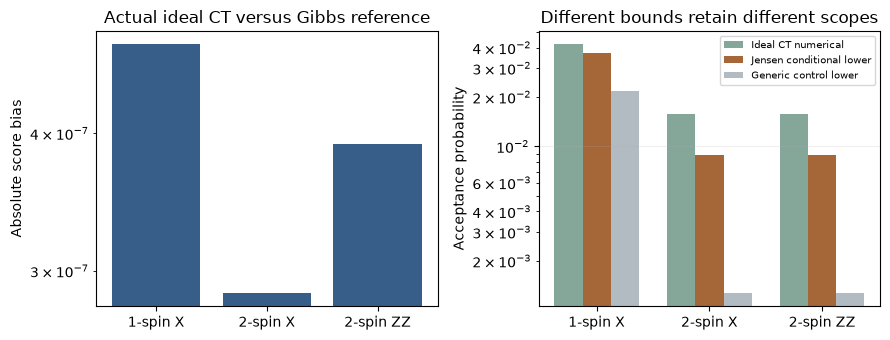

In [3]:
thermal=[]
for name in ("thermal-n1-X","thermal-n2-X","thermal-n2-Z"):
    saved=records[name]["prepared"]
    contract=saved["error_and_conditioning_contract"]
    thermal.append({"task":name,"wires":saved["source_logical_qubits"],
        "exact_score":saved["exact_reference_mean"],"fresh_source_score":fresh[name]["mean"],
        "actual_CT_score":saved["clifford_t_instrument_check"]["mean"],
        "actual_CT_acceptance":saved["clifford_t_instrument_check"]["acceptance_probability"],
        "conditional_lower_proposal":contract["acceptance_lower_proposal"],
        "generic_control_lower":contract["generic_acceptance_lower_control"]})
table(pd.DataFrame(thermal))
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
x=np.arange(3)
axes[0].bar(x,[max(abs(r["actual_CT_score"]-r["exact_score"]),1e-16) for r in thermal],color="#365e88")
axes[0].set(xticks=x,xticklabels=["1-spin X","2-spin X","2-spin ZZ"],yscale="log",ylabel="Absolute score bias",title="Actual ideal CT versus Gibbs reference")
for offset,(key,label,color) in enumerate((("actual_CT_acceptance","Ideal CT numerical","#85a79a"),("conditional_lower_proposal","Jensen conditional lower","#a56737"),("generic_control_lower","Generic control lower","#b2bbc2"))):
    axes[1].bar(x+(offset-1)*.25,[r[key] for r in thermal],width=.25,label=label,color=color)
axes[1].set(xticks=x,xticklabels=["1-spin X","2-spin X","2-spin ZZ"],yscale="log",ylabel="Acceptance probability",title="Different bounds retain different scopes")
axes[1].legend(fontsize=7)
for ax in axes: ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Accepted samples and complete retry populations

The task error target is 0.05: source bias 0.01, realization bias 0.01, statistical error 0.03. A total conditional failure allowance of 0.01 gives 0.0025 each to statistics, acceptance, physical faults and factory availability. Two-spin energy divides every allocation equally among X and Z groups.

Hoeffding sets the accepted score counts from the complete scalar score width. An outward interval calculation chooses a retry cap for each accepted slot. All capped attempts are charged, including failures; repeated circuits are not materialized. These populations are calculated and unexecuted.

,task,accepted_scores,complete_retries_per_slot,capped_complete_attempts,generic_control_attempts,previous_cap_minimality_proved
0,dynamics-n1-Z,14855,242,3594910,3594910,True
1,dynamics-n2-Z,14855,242,3594910,3594910,True
2,thermal-n1-X,1820,359,653380,1112020,True
3,thermal-n2-X,32135,1911,61409985,433340475,True
4,thermal-n2-Z,23609,1877,44314093,312606769,True


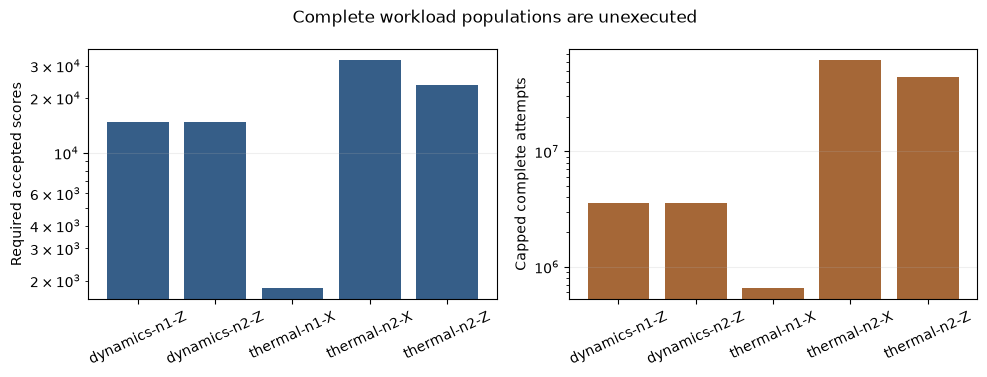

In [4]:
workload=[]
for name,entry in records.items():
    saved=entry["prepared"]
    w=saved["complete_workload"]
    workload.append({"task":name,"accepted_scores":w["accepted_slots"],
        "complete_retries_per_slot":w["retry_cap_per_accepted_slot"],
        "capped_complete_attempts":w["complete_attempts"],
        "generic_control_attempts":w["generic_target_bound_control_attempts"],
        "previous_cap_minimality_proved":w["minimality_proved_for_selected_lower_probability"]})
table(pd.DataFrame(workload))
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
names=[r["task"] for r in workload]
axes[0].bar(names,[r["accepted_scores"] for r in workload],color="#365e88")
axes[0].set_ylabel("Required accepted scores")
axes[1].bar(names,[r["capped_complete_attempts"] for r in workload],color="#a56737")
axes[1].set_ylabel("Capped complete attempts")
for ax in axes:
    ax.set_yscale("log")
    ax.tick_params(axis="x",rotation=25)
    ax.grid(axis="y",alpha=.2)
fig.suptitle("Complete workload populations are unexecuted")
fig.tight_layout()
plt.show()


## Keep the approximation stages separate

For scalar score width $W$, target-branch norm lower $s$, encoded source error $\epsilon$ and realization proposal $\eta$, the study uses

$$p_{\rm lower}=(s-\epsilon-\eta)^2,\quad B_{\rm source}\le2W\epsilon/s,\quad B_{\rm realization}\le2W\eta/(s-\epsilon).$$

Here $\eta$ is the guarded sum of **actual generated** numerical rotation errors plus the separate $10^{-7}$ SDK nested-control/routing reserve. The requested synthesis allowance is $5\times10^{-5}$. The source intervals do not certify the numerical synthesis guard or SDK reserve. Small outcome agreement does not prove a uniform norm bound. These coherent errors are not physical-fault probabilities.

,task,source_bias_upper,realization_bias_proposal,statistical_allowance,actual_guarded_synthesis_error,SDK_reserve_scenario
0,dynamics-n1-Z,3.258752e-07,0.000157,0.030,0.000010,1.000000e-07
1,dynamics-n2-Z,3.429588e-06,0.000138,0.030,0.000009,1.000000e-07
2,thermal-n1-X,2.030899e-08,0.000094,0.030,0.000013,1.000000e-07
3,thermal-n2-X,4.807280e-07,0.000238,0.015,0.000008,1.000000e-07
4,thermal-n2-Z,4.120525e-07,0.000204,0.015,0.000008,1.000000e-07


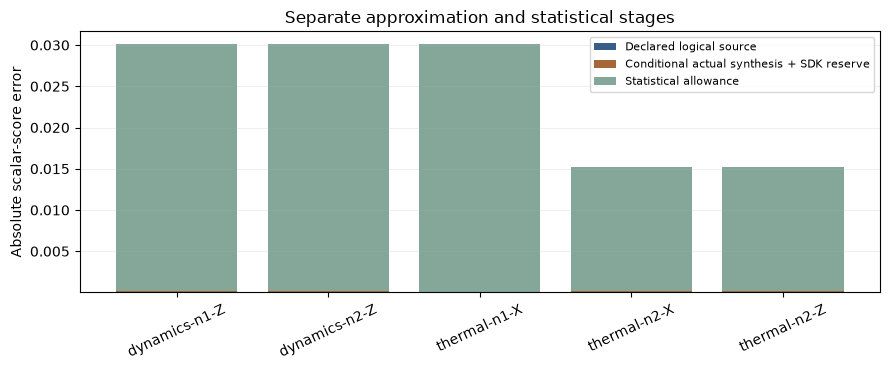

In [5]:
bias=[]
for name,entry in records.items():
    saved=entry["prepared"]
    c=saved["error_and_conditioning_contract"]
    bias.append({"task":name,"source_bias_upper":c["source_score_bias_upper"],
        "realization_bias_proposal":c["realization_score_bias_upper_proposal"],
        "statistical_allowance":saved["statistical_absolute_error"],
        "actual_guarded_synthesis_error":saved["actual_synthesis"]["guarded_numerical_operator_error_upper_estimate"],
        "SDK_reserve_scenario":c["nested_control_routing_allowance_scenario"]})
table(pd.DataFrame(bias))
x=np.arange(len(bias))
source=np.array([r["source_bias_upper"] for r in bias])
realization=np.array([r["realization_bias_proposal"] for r in bias])
statistical=np.array([r["statistical_allowance"] for r in bias])
fig,ax=plt.subplots(figsize=(9,3.8))
ax.bar(x,source,label="Declared logical source",color="#365e88")
ax.bar(x,realization,bottom=source,label="Conditional actual synthesis + SDK reserve",color="#a56737")
ax.bar(x,statistical,bottom=source+realization,label="Statistical allowance",color="#85a79a")
ax.set(xticks=x,xticklabels=[r["task"] for r in bias],ylabel="Absolute scalar-score error",title="Separate approximation and statistical stages")
ax.tick_params(axis="x",rotation=25)
ax.legend(fontsize=8)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Conditional physical scenarios and one shared energy configuration

Physical error $10^{-3}$ or $10^{-4}$ is crossed with controller failure $10^{-15}$ per decision, then with the separate conditional controller premise $10^{-18}$. All other profile assumptions remain unchanged. A distance-independent controller term can make the additive model infeasible; it is not a calibrated lower bound on actual hardware failure.

The serialized model charges complete algorithm attempts, startup/reset/readout, controller dispatch, idle exposure, neighboring transport, T injection/correction, complete factory retries and extra handoff residence. It is a separate scenario preserving the frozen Grover/PSSPC baseline. Two-spin X/Z energy candidates use the same distance, reserved patches, factory size, pipeline time and output error; runtime and failure allocations add, sequential peak qubits take the maximum. Infeasible scenarios remain in the table.

,task,scenario,status,complete_attempts,data_code_distance,peak_physical_qubits,runtime_all_attempts_hours
0,dynamics-n1-Z,p1e-03-controller1e-15,computed_conditional_instrument_surface_code_m...,3594910,37.0,1015427.0,6.320377e+04
1,dynamics-n1-Z,p1e-04-controller1e-15,computed_conditional_instrument_surface_code_m...,3594910,19.0,253071.0,3.587793e+04
2,dynamics-n1-Z,p1e-03-controller1e-18,computed_conditional_instrument_surface_code_m...,3594910,33.0,807667.0,5.713136e+04
3,dynamics-n1-Z,p1e-04-controller1e-18,computed_conditional_instrument_surface_code_m...,3594910,17.0,202527.0,3.284172e+04
4,dynamics-n2-Z,p1e-03-controller1e-15,infeasible_declared_controller_model,3594910,NaN,NaN,NaN
5,dynamics-n2-Z,p1e-04-controller1e-15,infeasible_declared_controller_model,3594910,NaN,NaN,NaN
6,dynamics-n2-Z,p1e-03-controller1e-18,computed_conditional_instrument_surface_code_m...,3594910,37.0,1048271.0,3.815194e+05
7,dynamics-n2-Z,p1e-04-controller1e-18,computed_conditional_instrument_surface_code_m...,3594910,17.0,209451.0,2.029220e+05
8,thermal-n1-X,p1e-03-controller1e-15,computed_conditional_instrument_surface_code_m...,653380,33.0,816375.0,1.046269e+04
9,thermal-n1-X,p1e-04-controller1e-15,computed_conditional_instrument_surface_code_m...,653380,17.0,204835.0,6.099568e+03


,scenario,status,common_candidates,peak_qubits,runtime_hours
0,p1e-03-controller1e-15,no_common_feasible_configuration,0,NaN,NaN
1,p1e-04-controller1e-15,no_common_feasible_configuration,0,NaN,NaN
2,p1e-03-controller1e-18,computed_common_configuration_energy_model,35,1314151.0,1.460045e+07
3,p1e-04-controller1e-18,computed_common_configuration_energy_model,112,267491.0,7.762795e+06


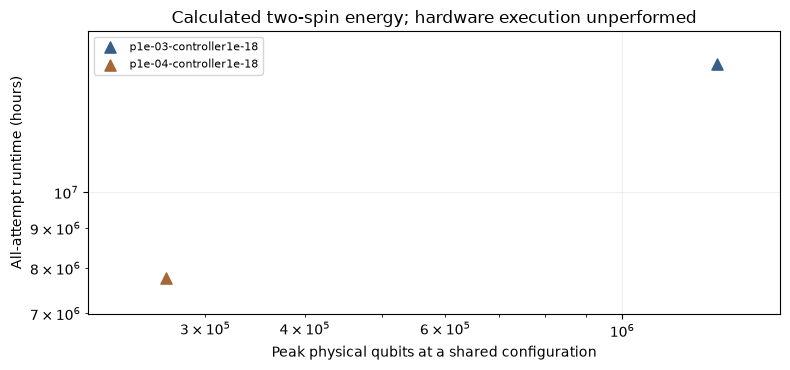

In [6]:
table(summary[["task","scenario","status","complete_attempts","data_code_distance","peak_physical_qubits","runtime_all_attempts_hours"]])
energy_rows=[]
for scenario,report in results["energy"].items():
    points=report["pareto_points"]
    point=min(points,key=lambda p:(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"])) if points else None
    if point:
        groups=point["group_points"]
        common=lambda p:(p["data_code_distance"],p["reserved_logical_patches"],p["factory_physical_qubits"],p["factory_supply"]["pipeline_time_ns"],p["factory_supply"]["output_error"])
        assert common(groups["X"])==common(groups["Z"])
        assert point["peak_physical_qubits"]==max(p["peak_physical_qubits"] for p in groups.values())
        assert point["worst_case_runtime_all_attempts_ns"]==sum(p["worst_case_runtime_all_attempts_ns"] for p in groups.values())
    energy_rows.append({"scenario":scenario,"status":report["status"],
        "common_candidates":report["common_feasible_candidate_count"],
        "peak_qubits":point["peak_physical_qubits"] if point else None,
        "runtime_hours":point["worst_case_runtime_all_attempts_ns"]/3.6e12 if point else None})
table(pd.DataFrame(energy_rows))
fig,ax=plt.subplots(figsize=(8,3.8))
feasible=[r for r in energy_rows if r["peak_qubits"] is not None]
for i,row in enumerate(feasible):
    ax.scatter(row["peak_qubits"],row["runtime_hours"],s=65,marker="o" if "controller1e-15" in row["scenario"] else "^",color=("#365e88" if "p1e-03" in row["scenario"] else "#a56737"),label=row["scenario"])
if feasible:
    ax.set(xscale="log",yscale="log",xlim=(min(r["peak_qubits"] for r in feasible)*.8,max(r["peak_qubits"] for r in feasible)*1.2),ylim=(min(r["runtime_hours"] for r in feasible)*.9,max(r["runtime_hours"] for r in feasible)*1.1))
    ax.legend(loc="upper left",fontsize=8)
else:
    ax.text(.5,.5,"No common feasible energy configuration in the declared model",ha="center",va="center",transform=ax.transAxes)
ax.set(xlabel="Peak physical qubits at a shared configuration",ylabel="All-attempt runtime (hours)",title="Calculated two-spin energy; hardware execution unperformed")
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


## Reproduction, provenance and separate caps

The complete-resource generator supplies source and actual Clifford+T QASMs, exact sequence/source hashes, source/realization/acceptance/statistical contracts, all physical scenarios and common-configuration energy reports. The pinned exporter omits overall global phase, so these measured-trial QASMs are not a phase-preserving controlled-oracle specification. SABRE uses seed 7; the native synthesizer exposes no seed argument.

This study is limited to one/two system spins, eight total wires, 20,000 source instructions, 500,000 synthesized/check instructions, 256 weighted simulator branches and $10^{12}$ calculated complete attempts. The older scalable generators have different materialization/simulation caps. Formal synthesis, interface layout, decoder throughput and hardware validation remain unavailable. Offline coefficient/circuit/synthesis processing and final statistical reporting wall time are outside quantum runtime.

In the source checkout use `PYTHONPATH=src python scripts/generate_simulation_complete_resources.py`. For an independent notebook run, save every copied Python source, manifest/results/CSV, case subdirectories, lock, license and references beside this notebook. Fresh execution performs only bounded source checks and loads the saved synthesis/model evidence; no GPU or remote job is launched.

In [7]:
assert manifest["public_bundle_contains_private_cache"] is False
assert manifest["synthesis_seed"] is None
assert manifest["transpiler_seed"]==7
assert manifest["frozen_baseline_before"]==manifest["frozen_baseline_after"]
for name,entry in records.items():
    saved=entry["prepared"]
    assert saved["hardware_workload_executed"] is False
    assert saved["actual_synthesis"]["actual_synthesis_sequences_generated"] is True
    assert saved["actual_synthesis"]["preserve_full_unitary"] is True
    for qasm,expected in saved["qasm_sha256"].items():
        assert hashlib.sha256((asset_dir/name/qasm).read_bytes()).hexdigest()==expected
print("Saved sequence identities, frozen-baseline fingerprints, explicit caps and unexecuted-workload labels verified.")
print("Recorded package versions:",manifest["packages"])


Saved sequence identities, frozen-baseline fingerprints, explicit caps and unexecuted-workload labels verified.
Recorded package versions: {'qiskit': '2.6.2', 'qdk': '1.34.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}
